In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV,ElasticNetCV, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

Подключение библиотек:
- numpy и pandas - для математических вычислений, загрузки и обработки табличных данных
- matplotlib.pyplot и seaborn - для визуализации данных
- sklearn.model_selection - для разделения данных на обучающую и тестовую выборки
- sklearn.preprocessing - для масштабирования признаков
- sklearn.linear_model - для построения и сравнения линейных моделей
- sklearn.metrics - для оценки качества моделей

In [4]:
df = pd.read_csv("Housing.csv")
df = df.drop(columns=["date"])
#df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())

df = pd.get_dummies(df, drop_first=True)

X = df.drop(["price", "id", "zipcode", "lat", "long"], axis=1)
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train=scaler.fit_transform(X_train) 
X_test=scaler.transform(X_test)

corr_matrix = X.corr()

print("Матрица корреляций")
display(corr_matrix.round(2))

Матрица корреляций


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
bedrooms,1.00,0.52,0.58,0.03,0.18,-0.01,0.08,0.03,0.36,0.48,0.30,0.15,0.02,0.39,0.03
bathrooms,0.52,1.00,0.75,0.09,0.50,0.06,0.19,-0.12,0.66,0.69,0.28,0.51,0.05,0.57,0.09
sqft_living,0.58,0.75,1.00,0.17,0.35,0.10,0.28,-0.06,0.76,0.88,0.44,0.32,0.06,0.76,0.18
sqft_lot,0.03,0.09,0.17,1.00,-0.01,0.02,0.07,-0.01,0.11,0.18,0.02,0.05,0.01,0.14,0.72
floors,0.18,0.50,0.35,-0.01,1.00,0.02,0.03,-0.26,0.46,0.52,-0.25,0.49,0.01,0.28,-0.01
waterfront,-0.01,0.06,0.10,0.02,0.02,1.00,0.40,0.02,0.08,0.07,0.08,-0.03,0.09,0.09,0.03
view,0.08,0.19,0.28,0.07,0.03,0.40,1.00,0.05,0.25,0.17,0.28,-0.05,0.10,0.28,0.07
condition,0.03,-0.12,-0.06,-0.01,-0.26,0.02,0.05,1.00,-0.14,-0.16,0.17,-0.36,-0.06,-0.09,-0.00
grade,0.36,0.66,0.76,0.11,0.46,0.08,0.25,-0.14,1.00,0.76,0.17,0.45,0.01,0.71,0.12
sqft_above,0.48,0.69,0.88,0.18,0.52,0.07,0.17,-0.16,0.76,1.00,-0.05,0.42,0.02,0.73,0.19


Были удалены следующие столбцы, поскольку не имеют смысла: "id" - это уникальный идентификатор, "zipcode" - почтовый индекс, "lat" и "long" - географические координаты.

В матрице корреляций можно увидеть наибольшую корреляцию между следующими признаками:

- sqft_living и bathrooms - 0,75 (общая площадь жилого помещения и кол-во ванных комнат)
- sqft_living и grade - 0,76 (общая площадь жилого помещения и общий рейтинг дома)
- sqft_living и sqft_above - 0,88 (общая площадь жилого помещения и общая площадь помещения выше уровня земли)
- sqft_living и sqft_living15 - 0,76 (общая площадь жилого помещения и ср. площадь ближайших 15 домов соседей)
- sqft_lot15 и sqft_lot - 0,72 (ср. площадь участков ближайших 15 домов соседей и площадь участка)
- sqft_lot15 и grade 0,71 - (ср. площадь участков ближайших 15 домов соседей и общий рейтинг дома)
- sqft_above и sqft_living15 - 0,73 (общая площадь помещения выше уровня земли и ср. площадь участков ближайших 15 домов соседей)
- sqft_above и grade - 0,76 (общая площадь помещения выше уровня земли и общий рейтинг дома)

Признак корреляции больше 0,85 только у одной пары - sqft_living и sqft_above (0,88) - общая площадь жилого помещения и общая площадь помещения выше уровня земли. Они линейно зависимы

In [5]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 2000.0, 3000.0, 5000.0, 10000.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)


lasso_cv =LassoCV(alphas=alphas_to_test, random_state=42, max_iter=10000)
lasso_cv.fit(X_train, y_train)
lasso =Lasso(alpha=5000.0, random_state=42)
lasso.fit(X_train, y_train)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5, random_state=42, max_iter=10000)
elastic_cv.fit(X_train, y_train)

print(f"alpha l2= {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print(f"alpha l1/l2 = {elastic_cv.alpha_}")
print(f"Оптимальное соотношение L1/L2 (l1_ratio): {elastic_cv.l1_ratio_}")

print("Веса OLS")
print(np.round(lr.coef_, 0))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 0))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 0))
print("Веса Lasso (L1) (alpha = 5000)")
print(np.round(lasso.coef_, 0))
print("Веса ElasticNet:")
print(np.round(elastic_cv.coef_, 0))

alpha l2= 100.0
alpha l1 = 100.0
alpha l1/l2 = 0.1
Оптимальное соотношение L1/L2 (l1_ratio): 0.95
Веса OLS
[ -35963.   37549.   74674.   -1757.   15266.   46882.   33348.   11189.
  138172.   62932.   36571. -106606.    4346.   17360.  -12688.]
Веса Ridge (L2)
[ -35336.   37178.   74489.   -1736.   15335.   46648.   33583.   11416.
  136335.   62724.   36578. -105094.    4716.   18260.  -12606.]
Веса Lasso (L1)
[ -35685.   37398.  144122.   -1688.   15096.   46818.   33371.   11092.
  138156.       0.    2875. -106396.    4300.   17246.  -12618.]
Веса Lasso (L1) (alpha = 5000)
[-22277.  29466. 141418.     -0.   7485.  43703.  34221.   6246. 137619.
      0.      0. -95949.   2068.  11745.  -7846.]
Веса ElasticNet:
[ -35420.   37227.   74519.   -1738.   15326.   46680.   33552.   11386.
  136580.   62748.   36575. -105296.    4667.   18140.  -12618.]


Вывод:
- Веса OLS. Очень большие веса - 138172 и -106606, признак мультиколлинерности
- Веса Ridge (L2). Веса чуть-чуть сжались, теперь - 136335 и -105094, нулевых весов не появилось
- Веса Lasso (L1). Один из признаков обнулился
- Веса Lasso (L1) (alpha = 5000). Обнулились три признака (чем выше штраф alpha, тем жестче Lasso отбрасывает признаки)
- Веса ElasticNet. Нулевых весов нет, веса практически совпадают с Ridge.

Оптимальное соотношение L1/L2 (l1_ratio): 0.95 означает, что модель использует 95% L1-регуляризации и 5% L2-регуляризации, то есть почти целиком опирается на Lasso, но L2-регуляризация стабилизирует веса и предотвращает их полное обнуление


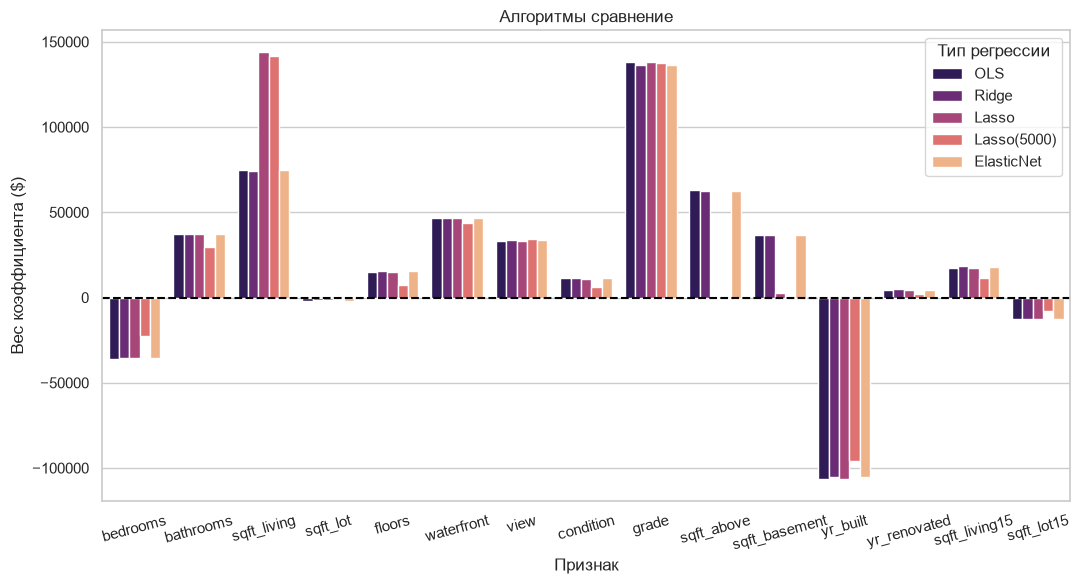

In [6]:
weights_df = pd.DataFrame(
    {
        "Признак" : X.columns,
        "OLS" : lr.coef_,
        "Ridge" : ridge_cv.coef_,
        "Lasso" : lasso_cv.coef_,
        "Lasso(5000)" : lasso.coef_,
        "ElasticNet": elastic_cv.coef_
    }
)
weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на цену (Вес)" 
)
plt.figure(figsize=(11,6))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на цену (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Алгоритмы сравнение")
plt.ylabel("Вес коэффициента ($)", fontsize=12)
plt.xticks(rotation=15)
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()

На графике представлена визуализация распределения весов между моделями. Наибольшие веса у grade (общий рейтинг дома), sqft_living (общая площадь жилого помещения) и yr_build (год постройки). Обнулились признаки у sqft_lot (площадь участка), sqft_above (площадь жилого помещения выше уровня земли) и sqft_basement (площадь подвала)

Анализ весов моделей демонстрирует, как регуляризация решает проблему мультиколлинеарности. Модель OLS выдала очень большие веса, т.е. она не смогла корректно разделить влияние коррелирующих признаков. Применение регуляризации стабилизировало модель: Ridge незначительно сжала эти значения, сохранив все признаки, Lasso обнулила один признак, а при alpha=5000 обнулила уже три признака, убрав таким образом ненужные признаки. Модель ElasticNet имеет L1-регуляризацию для отсеивания лишних данных и немного L2 для предотвращения схлопывания весов. Таким образом, регуляризация сделала модель более устойчивой.

In [47]:
print(f"R2 для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R2 для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"R2 для ElasticNet: {r2_score(y_test, elastic_cv.predict(X_test)):.4f}")

R2 для OLS: 0.6541
R2 для Ridge: 0.6540
R2 для Lasso: 0.6541
R2 для Lasso: 0.6508
R2 для ElasticNet: 0.6540


R2 у всех моделей примерно одинаковое, то есть качество предсказаний при использовании регуляризации не поменялось. Только у Lasso при alpha=5000 можно заметить небольшое снижение R2 (по сравнению с остальными). Можно сделать вывод, что при изменении жесткости отсеивания признаков точность предсказаний может снизиться. 

Таким образом, по результатам регуляризации получились более устойчивые модели, при alpha=100 модель обнулила вес у sqft_above, а при alpha=5000 обнулила вес у трех признаков - sqft_lot, sqft_basement и sqft_above. 